# wms-bug-reproj

Compute a **normal map** from heights retrieved with the [Geoplateforme WMS-R service](https://data.geopf.fr/wms-r/wms) (`format=image/x-bil;bits=32` returns raw `float32` heights) and show why the request must **stay in the native projection of the data**.

A WMS server always returns the requested grid (`CRS`, `BBOX`, `WIDTH`, `HEIGHT`). When this grid does not match the grid of the stored data, the server **resamples** the heights. Here, the resampling duplicates some rows/columns: the heights look fine, but the gradients (and therefore the normals) show **stripes**.

To avoid it:

* request the data in the **projection in which it is stored** (see the `CRS` of the layer in the `GetCapabilities` response),
* use a **resolution and a `BBOX` aligned with the stored grid**.

The same area (Mont Blanc massif) is requested three times:

1. `ELEVATION.ELEVATIONGRIDCOVERAGE.HIGHRES` in Web Mercator (`EPSG:3857`): stripes,
2. the same layer in Lambert 93 (`EPSG:2154`): still artifacts, because this layer is stored in geographic coordinates (`IGNF:WGS84G`),
3. `RGEALTI-MNT_PYR-ZIP_FXX_LAMB93_WMS` in Lambert 93 (`EPSG:2154`), the native projection of this layer, with an aligned grid: clean result.

In [1]:
import math
import os
import requests
import numpy as np
from PIL import Image

WMS_URL = "https://data.geopf.fr/wms-r/wms"

# size of the normal map (one extra pixel is requested on each side to compute gradients)
N = 128

os.makedirs('output', exist_ok=True)


def get_heights(layer, crs, bbox):
    """Retrieve (N+2)x(N+2) heights as float32 using a WMS GetMap request."""
    params = {
        'SERVICE': 'WMS',
        'VERSION': '1.3.0',
        'REQUEST': 'GetMap',
        'LAYERS': layer,
        'STYLES': '',
        'CRS': crs,
        'BBOX': ','.join(str(v) for v in bbox),
        'WIDTH': N + 2,
        'HEIGHT': N + 2,
        'FORMAT': 'image/x-bil;bits=32',
    }
    response = requests.get(WMS_URL, params=params)
    response.raise_for_status()
    if not response.headers['Content-Type'].startswith('image/x-bil'):
        raise RuntimeError(response.text)
    return np.frombuffer(response.content, dtype=np.float32).reshape((N + 2, N + 2))


def compute_normals(heights, dx, dy):
    """Compute normals using central differences.

    dx and dy are the pixel sizes in meters on the ground. Rows go from north to south.
    """
    dz_dx = (heights[1:-1, 2:] - heights[1:-1, :-2]) / (2.0 * dx)
    dz_dy = (heights[:-2, 1:-1] - heights[2:, 1:-1]) / (2.0 * dy)
    normals = np.stack([-dz_dx, -dz_dy, np.ones_like(dz_dx)], axis=-1)
    return normals / np.linalg.norm(normals, axis=-1, keepdims=True)


def render(name, heights, normals):
    """Display and save heights (grayscale) and normals (RGB, [-1,1] mapped to [0,255])."""
    heights = heights[1:-1, 1:-1]
    z_min, z_max = np.min(heights), np.max(heights)
    print(f'z_min={z_min:.2f}, z_max={z_max:.2f}')
    img_heights = Image.fromarray(np.uint8(np.round(255.0 * (heights - z_min) / (z_max - z_min))), 'L')
    img_normals = Image.fromarray(np.uint8(np.round((normals + 1.0) * 0.5 * 255.0)), 'RGB')
    img_heights.save(f'output/{name}-heights.png')
    img_normals.save(f'output/{name}-normals.png')
    both = Image.new('RGB', (2 * N + 8, N), 'white')
    both.paste(img_heights.convert('RGB'), (0, 0))
    both.paste(img_normals, (N + 8, 0))
    display(both.resize((both.width * 3, both.height * 3), Image.NEAREST))


def duplicated_rows(heights):
    """Ratio of rows identical to the previous one (sign of a resampling with duplicated values)."""
    return np.mean(np.all(np.diff(heights, axis=0) == 0.0, axis=1))

## 1. Web Mercator (EPSG:3857)

`ELEVATION.ELEVATIONGRIDCOVERAGE.HIGHRES` is stored in geographic coordinates (`IGNF:WGS84G`). Requesting it in `EPSG:3857` with an arbitrary resolution forces the server to reproject and resample the heights: some rows are duplicated and the normal map shows **horizontal stripes**.

Note that Web Mercator distances are not ground distances: they must be multiplied by `cos(latitude)` (≈ 0.70 here), otherwise slopes are underestimated.

latitude=45.8862, pixel size on the ground=6.57 m
duplicated rows: 31%
z_min=2437.34, z_max=3561.50


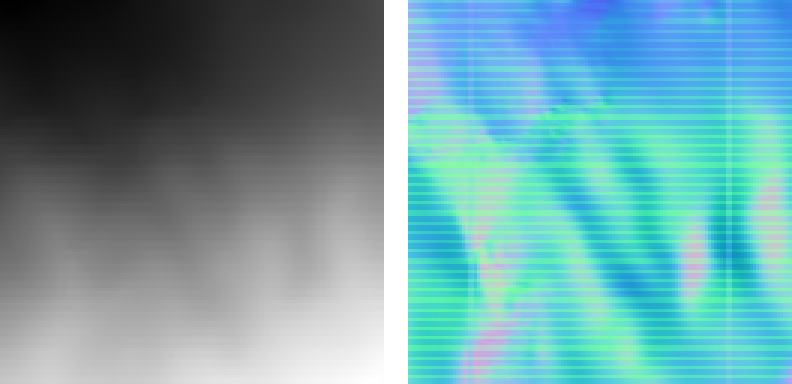

In [2]:
bbox = [766813.8789930125, 5761515.054564301, 768041.6487596722, 5762742.824330961]
heights = get_heights('ELEVATION.ELEVATIONGRIDCOVERAGE.HIGHRES', 'EPSG:3857', bbox)

# pixel size in meters on the ground (Web Mercator scale factor is 1/cos(latitude))
lat = math.degrees(math.atan(math.sinh((bbox[1] + bbox[3]) / 2.0 / 6378137.0)))
scale = math.cos(math.radians(lat))
dx = (bbox[2] - bbox[0]) / (N + 2) * scale
dy = (bbox[3] - bbox[1]) / (N + 2) * scale
print(f'latitude={lat:.4f}, pixel size on the ground={dx:.2f} m')
print(f'duplicated rows: {duplicated_rows(heights):.0%}')

render('epsg-3857', heights, compute_normals(heights, dx, dy))

## 2. Lambert 93 (EPSG:2154) with the same layer

Requesting Lambert 93 is not enough: `ELEVATION.ELEVATIONGRIDCOVERAGE.HIGHRES` is still reprojected from `IGNF:WGS84G` and the stored grid is slightly rotated compared to the Lambert 93 grid, hence **oblique stripes**.

z_min=2490.84, z_max=3442.59


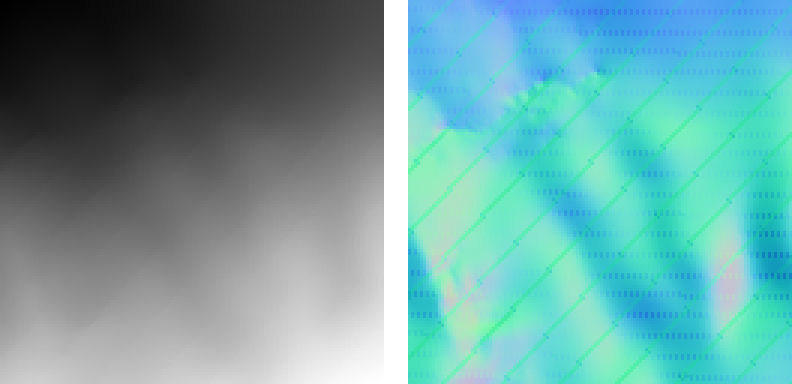

In [3]:
# same area in Lambert 93, 5 m pixels
RES = 5.0
x0, y0 = 1001540.5, 6538955.5
bbox = [x0, y0, x0 + (N + 2) * RES, y0 + (N + 2) * RES]

heights = get_heights('ELEVATION.ELEVATIONGRIDCOVERAGE.HIGHRES', 'EPSG:2154', bbox)
render('epsg-2154-highres', heights, compute_normals(heights, RES, RES))

## 3. Lambert 93 (EPSG:2154) with a layer stored in Lambert 93

`RGEALTI-MNT_PYR-ZIP_FXX_LAMB93_WMS` is stored in Lambert 93 (`IGNF:LAMB93`) on a 1 m grid whose pixel edges are at `x.5` meters. With a `BBOX` aligned on this grid, there is no reprojection and the normal map is clean.

The resolution still matters: in this mountain area, multiples of 5 m give a clean result while 4, 6 or 8 m show a grid pattern (the RGE ALTI is derived from coarser sources in some areas).

duplicated rows: 0%
z_min=2489.85, z_max=3443.36


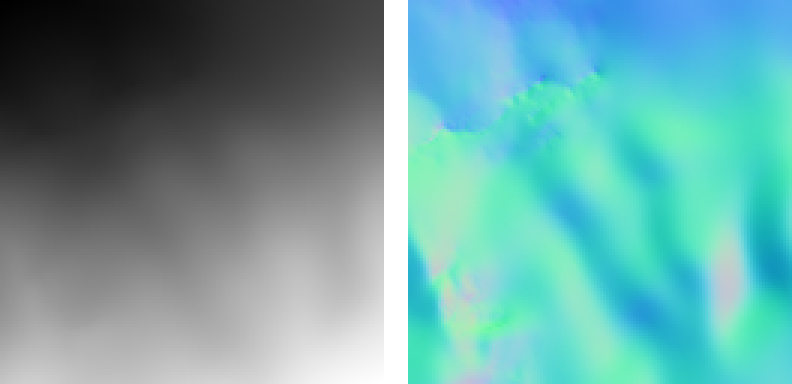

In [4]:
# same bbox as above: aligned on the 1 m grid of the layer (pixel edges at x.5) with 5 m pixels
heights = get_heights('RGEALTI-MNT_PYR-ZIP_FXX_LAMB93_WMS', 'EPSG:2154', bbox)
print(f'duplicated rows: {duplicated_rows(heights):.0%}')
render('epsg-2154-lamb93', heights, compute_normals(heights, RES, RES))